# Теория экстремальных значений: предельные распределения против нормального закона

Центральная предельная теорема говорит, как ведут себя **суммы и средние**: при широких условиях они сходятся к нормальному закону. Но во многих задачах важна не сумма, а **максимум**: самый высокий паводок за год, самый большой дневной убыток портфеля, максимальная нагрузка на конструкцию за срок службы. Для максимумов существует своя предельная теорема — **теорема Фишера–Типпета–Гнеденко**:

> если нормированные максимумы $M_n = \max(X_1,\dots,X_n)$ независимых одинаково распределённых величин сходятся к невырожденному закону, то этот закон обязательно принадлежит одному из трёх типов — Гумбеля, Фреше или Вейбулла (или, что то же, обобщённому распределению экстремальных значений, GEV).

В этом ноутбуке:

1. запишем три типа и семью GEV явно и проверим формулы;
2. сравним их хвосты с нормальным законом;
3. смоделируем «многолетние» временные ряды, выделим годовые максимумы и посмотрим, как они ложатся на GEV — и как плохо их описывает нормальное распределение;
4. посчитаем уровни возврата («паводок раз в 100 лет») и увидим, во что обходится ошибка нормальной модели;
5. на одних и тех же данных сравним ЦПТ (суммы) и теорию экстремальных значений (максимумы).

## Три типа предельных распределений

Во всех формулах ниже $\mu\in\mathbb R$ — положение, $\sigma>0$ — масштаб.

### Тип I: распределение Гумбеля (Gumbel)

$$G(x)=\exp\left[-\exp\left(-\frac{x-\mu}{\sigma}\right)\right],\qquad x\in\mathbb R.$$

- Хвост убывает экспоненциально или быстрее.
- Типичные области применения: экстремальные температуры и уровни рек; при подходящих хвостовых предпосылках — страховые убытки.

### Тип II: распределение Фреше (Fréchet)

$$
G(x)=
\begin{cases}
0, & x\le\mu,\\
\exp\left[-\left(\dfrac{x-\mu}{\sigma}\right)^{-\alpha}\right], & x>\mu,
\end{cases}
\qquad \alpha>0.
$$

- Тяжёлый хвост со степенным убыванием; $\alpha$ — хвостовой индекс.
- Примеры: крупные финансовые потери, размеры катастроф, очень высокие доходы.

### Тип III: распределение Вейбулла (Weibull)

$$
G(x)=
\begin{cases}
\exp\left[-\left(-\dfrac{x-\mu}{\sigma}\right)^\alpha\right], & x<\mu,\\
1, & x\ge\mu,
\end{cases}
\qquad \alpha>0.
$$

- Правый хвост ограничен конечной верхней границей $\mu$.
- Примеры: предельная прочность материалов, пределы усталости и ограниченные времена до отказа.

### Обобщённое распределение экстремальных значений (GEV)

Три типа объединяются в параметрическую семью

$$G(x;\mu,\sigma,\xi)=\exp\left\{-\left[1+\xi\left(\frac{x-\mu}{\sigma}\right)\right]^{-1/\xi}\right\},$$

определённую при $1+\xi(x-\mu)/\sigma>0$. Параметры:

- $\mu\in\mathbb R$ — положение (*location*);
- $\sigma>0$ — масштаб (*scale*);
- $\xi\in\mathbb R$ — форма (*shape*): $\xi=0$ соответствует типу Гумбеля, $\xi>0$ — Фреше, $\xi<0$ — Вейбулла.

При $\xi\to0$ непрерывный предел равен

$$\lim_{\xi\to0}G(x;\mu,\sigma,\xi)=\exp\left[-\exp\left(-\frac{x-\mu}{\sigma}\right)\right].$$

> **Важно про `scipy`.** В `scipy.stats.genextreme` параметр формы называется `c` и имеет **обратный знак**: `c = -ξ`. Тип II в `scipy` — это `invweibull`, тип III — `weibull_max`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.titleweight': 'bold',
    'axes.titlesize': 11,
    'legend.frameon': True,
    'legend.framealpha': 0.85,
    'legend.edgecolor': 'none',
    'legend.fontsize': 9,
    'lines.linewidth': 2,
})

# Цвет закреплён за моделью и не меняется по всему ноутбуку
COLORS = {
    'gumbel':  '#2a78d6',   # Тип I
    'frechet': '#eb6834',   # Тип II
    'weibull': '#1baf7a',   # Тип III
    'gev':     '#6250d6',   # подогнанная GEV
    'normal':  '#52514e',   # нормальный закон — нейтральный эталон
    'data':    '#a8a7a2',   # сырые наблюдения
    'max':     '#e34948',   # блочные максимумы
}

rng = np.random.default_rng(2026)

## 1. Формулы в коде и проверка

Запишем функции распределения ровно так, как в формулах выше, и сверим их с реализациями `scipy`. Заодно проверим, что типы II и III — это частные случаи GEV:

- Фреше$(\mu,\sigma,\alpha)$ = GEV$(\mu+\sigma,\ \sigma/\alpha,\ \xi=1/\alpha)$;
- Вейбулл$(\mu,\sigma,\alpha)$ = GEV$(\mu-\sigma,\ \sigma/\alpha,\ \xi=-1/\alpha)$.

In [2]:
def gumbel_cdf(x, mu=0.0, sigma=1.0):
    z = (np.asarray(x, float) - mu) / sigma
    return np.exp(-np.exp(-z))


def frechet_cdf(x, mu=0.0, sigma=1.0, alpha=1.0):
    z = (np.asarray(x, float) - mu) / sigma
    out = np.zeros_like(z)
    pos = z > 0
    out[pos] = np.exp(-z[pos] ** (-alpha))
    return out


def weibull_cdf(x, mu=0.0, sigma=1.0, alpha=1.0):
    z = (np.asarray(x, float) - mu) / sigma
    out = np.ones_like(z)
    neg = z < 0
    out[neg] = np.exp(-(-z[neg]) ** alpha)
    return out


def gev_cdf(x, mu=0.0, sigma=1.0, xi=0.0):
    z = (np.asarray(x, float) - mu) / sigma
    if abs(xi) < 1e-12:
        return gumbel_cdf(x, mu, sigma)
    t = 1 + xi * z
    # вне носителя: слева от нижней границы (ξ>0) G=0, справа от верхней (ξ<0) G=1
    out = np.full_like(z, 0.0 if xi > 0 else 1.0)
    ok = t > 0
    out[ok] = np.exp(-t[ok] ** (-1 / xi))
    return out


x = np.linspace(-6, 10, 4001)
mu, sigma, alpha = 0.5, 1.5, 3.0
checks = {
    'Гумбель vs scipy.gumbel_r':      (gumbel_cdf(x, mu, sigma),
                                       stats.gumbel_r(loc=mu, scale=sigma).cdf(x)),
    'Фреше vs scipy.invweibull':      (frechet_cdf(x, mu, sigma, alpha),
                                       stats.invweibull(c=alpha, loc=mu, scale=sigma).cdf(x)),
    'Вейбулл vs scipy.weibull_max':   (weibull_cdf(x, mu, sigma, alpha),
                                       stats.weibull_max(c=alpha, loc=mu, scale=sigma).cdf(x)),
    'GEV(ξ=0.3) vs scipy (c=-0.3)':   (gev_cdf(x, mu, sigma, 0.3),
                                       stats.genextreme(c=-0.3, loc=mu, scale=sigma).cdf(x)),
    'Фреше = GEV(ξ=1/α)':             (frechet_cdf(x, mu, sigma, alpha),
                                       gev_cdf(x, mu + sigma, sigma / alpha, 1 / alpha)),
    'Вейбулл = GEV(ξ=-1/α)':          (weibull_cdf(x, mu, sigma, alpha),
                                       gev_cdf(x, mu - sigma, sigma / alpha, -1 / alpha)),
}
for name, (a, b) in checks.items():
    print(f'{name:32s} max|разница| = {np.max(np.abs(a - b)):.1e}')

Гумбель vs scipy.gumbel_r        max|разница| = 0.0e+00
Фреше vs scipy.invweibull        max|разница| = 0.0e+00
Вейбулл vs scipy.weibull_max     max|разница| = 0.0e+00
GEV(ξ=0.3) vs scipy (c=-0.3)     max|разница| = 2.2e-16
Фреше = GEV(ξ=1/α)               max|разница| = 2.2e-16
Вейбулл = GEV(ξ=-1/α)            max|разница| = 2.2e-16


## 2. Чем предельные распределения отличаются от нормального

Возьмём по одному представителю каждого типа и сравним его с нормальным законом **с теми же средним и стандартным отклонением**. В «теле» распределения кривые похожи, поэтому по гистограмме разницу легко пропустить. Решающее отличие — в хвосте, поэтому во второй строке рисуем вероятность превышения $P(X>x)=1-G(x)$ в логарифмическом масштабе: там нормальный хвост — это парабола, уходящая вниз, Гумбель — прямая (экспоненциальный хвост), Фреше — медленно спадающая степенная кривая, а Вейбулл обрывается на верхней границе.

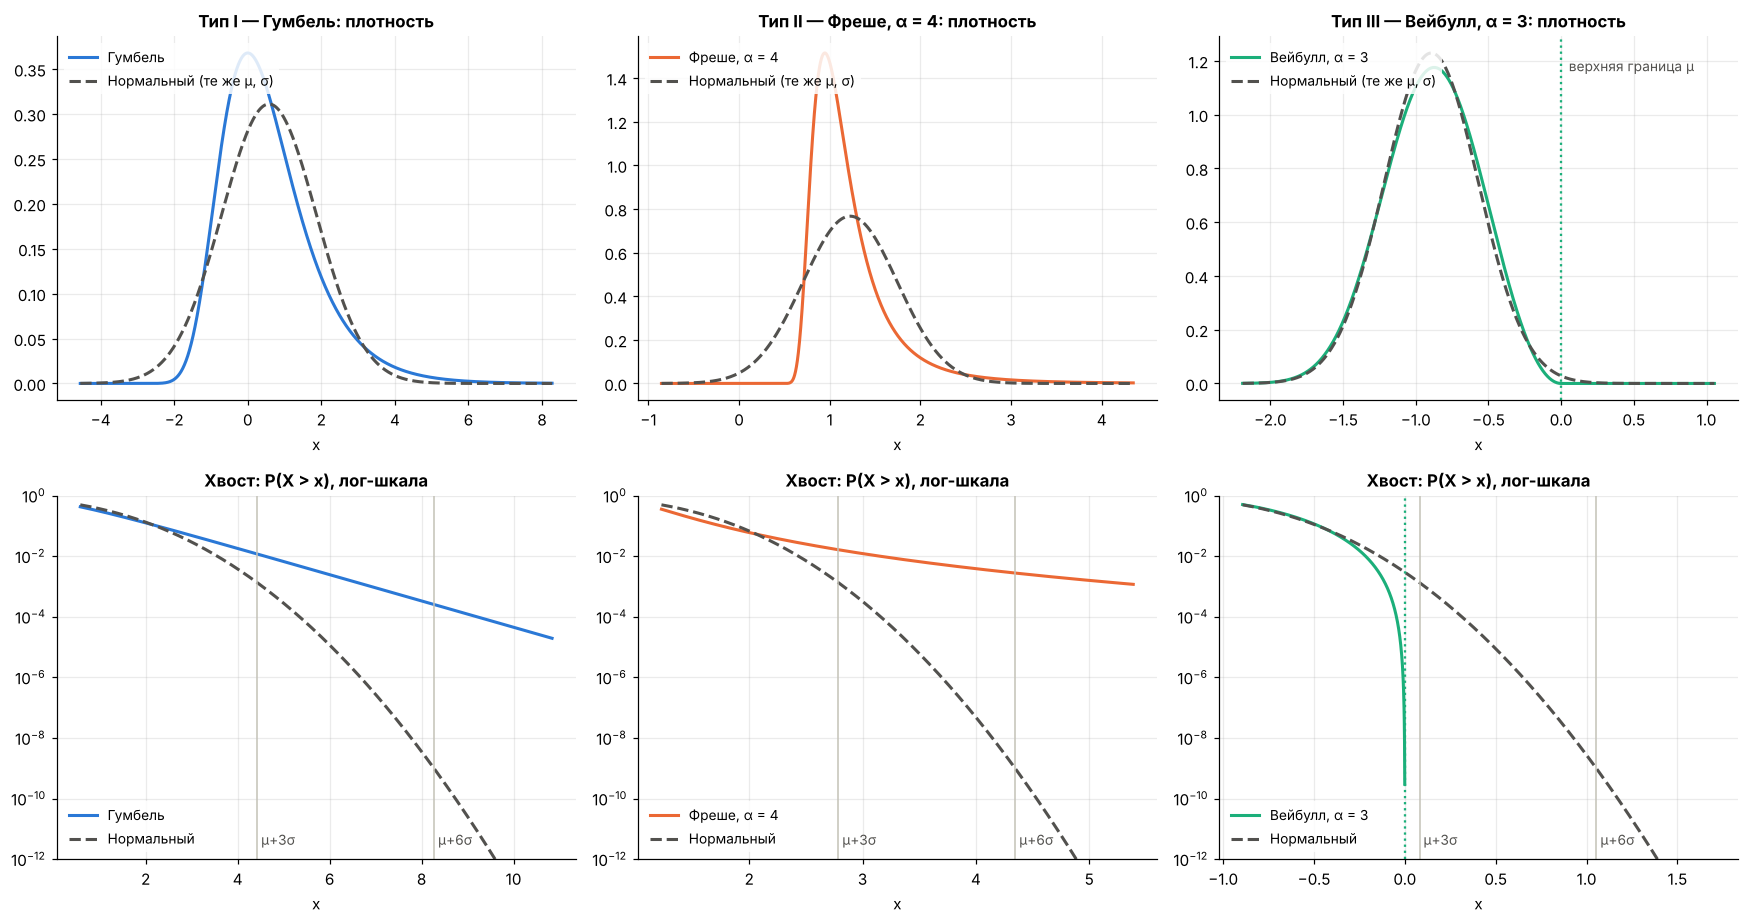

In [3]:
models = {
    'gumbel':  ('Тип I — Гумбель',          stats.gumbel_r(loc=0, scale=1)),
    'frechet': ('Тип II — Фреше, α = 4',    stats.invweibull(c=4, loc=0, scale=1)),
    'weibull': ('Тип III — Вейбулл, α = 3', stats.weibull_max(c=3, loc=0, scale=1)),
}

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for j, (key, (title, dist)) in enumerate(models.items()):
    m, s = dist.mean(), dist.std()
    nrm = stats.norm(m, s)
    upper = dist.support()[1]

    # плотность
    ax = axes[0, j]
    xs = np.linspace(m - 4 * s, m + 6 * s, 2000)
    ax.plot(xs, dist.pdf(xs), color=COLORS[key], label=title.split(' — ')[1])
    ax.plot(xs, nrm.pdf(xs), color=COLORS['normal'], ls='--', label='Нормальный (те же μ, σ)')
    if np.isfinite(upper):
        ax.axvline(upper, color=COLORS[key], ls=':', lw=1.5)
        ax.annotate('верхняя граница μ', (upper, ax.get_ylim()[1] * 0.9), xytext=(5, 0),
                    textcoords='offset points', fontsize=9, color='#52514e')
    ax.set_title(f'{title}: плотность')
    ax.set_xlabel('x')
    ax.legend(loc='upper left')

    # хвост в лог-масштабе
    ax = axes[1, j]
    xs = np.linspace(m, m + 8 * s, 2000)
    sf_model = dist.sf(xs)
    ax.semilogy(xs, np.where(sf_model > 0, sf_model, np.nan), color=COLORS[key],
                label=title.split(' — ')[1])
    ax.semilogy(xs, nrm.sf(xs), color=COLORS['normal'], ls='--', label='Нормальный')
    ax.set_ylim(1e-12, 1)
    for k in (3, 6):
        ax.axvline(m + k * s, color='#c3c2b7', lw=1)
        ax.text(m + k * s, 3e-12, f' μ+{k}σ', fontsize=9, color='#52514e')
    if np.isfinite(upper):
        ax.axvline(upper, color=COLORS[key], ls=':', lw=1.5)
    ax.set_title('Хвост: P(X > x), лог-шкала')
    ax.set_xlabel('x')
    ax.legend(loc='lower left')

fig.tight_layout()
plt.show()

Числами то же самое: насколько вероятность «события за $k$ сигм» у предельного распределения отличается от нормальной.

In [4]:
print(f'{"":26s}' + ''.join(f'{f"P(X > μ+{k}σ)":>16s}' for k in (2, 3, 4, 6)))
for key, (title, dist) in models.items():
    m, s = dist.mean(), dist.std()
    row = ''.join(f'{dist.sf(m + k * s):16.2e}' for k in (2, 3, 4, 6))
    print(f'{title:26s}{row}')
print(f'{"Нормальный":26s}' + ''.join(f'{stats.norm.sf(k):16.2e}' for k in (2, 3, 4, 6)))

                               P(X > μ+2σ)     P(X > μ+3σ)     P(X > μ+4σ)     P(X > μ+6σ)
Тип I — Гумбель                   4.23e-02        1.19e-02        3.32e-03        2.55e-04
Тип II — Фреше, α = 4             3.72e-02        1.64e-02        8.33e-03        2.79e-03
Тип III — Вейбулл, α = 3          1.44e-02        0.00e+00        0.00e+00        0.00e+00
Нормальный                        2.28e-02        1.35e-03        3.17e-05        9.87e-10


**Что видно:**

- Для Гумбеля событие «за 6σ» примерно в **сотни тысяч раз** вероятнее, чем предсказывает нормальный закон, для Фреше — в **миллионы раз**. Если моделировать максимумы нормальным распределением, катастрофические события объявляются «невозможными».
- Вейбулл, наоборот, имеет **жёсткий потолок**: выше $\mu$ значений нет вовсе, а нормальный закон приписывает таким значениям положительную вероятность (переоценивает риск — например, разрушения материала при нагрузке выше предела прочности).
- Все три распределения **асимметричны** (у Гумбеля коэффициент асимметрии ≈ 1.14), тогда как нормальный закон симметричен.

## 3. Семейство GEV: один параметр формы вместо трёх типов

Параметр формы $\xi$ плавно переводит одно распределение в другое. Ниже $\mu=0,\ \sigma=1$:

- $\xi<0$ (зелёные): появляется верхняя граница $x^*=\mu-\sigma/\xi$ — тип Вейбулла;
- $\xi=0$ (синяя): Гумбель;
- $\xi>0$ (оранжевые): появляется нижняя граница $\mu-\sigma/\xi$ и тяжёлый правый хвост $P(X>x)\sim x^{-1/\xi}$ — тип Фреше, хвостовой индекс $\alpha=1/\xi$.

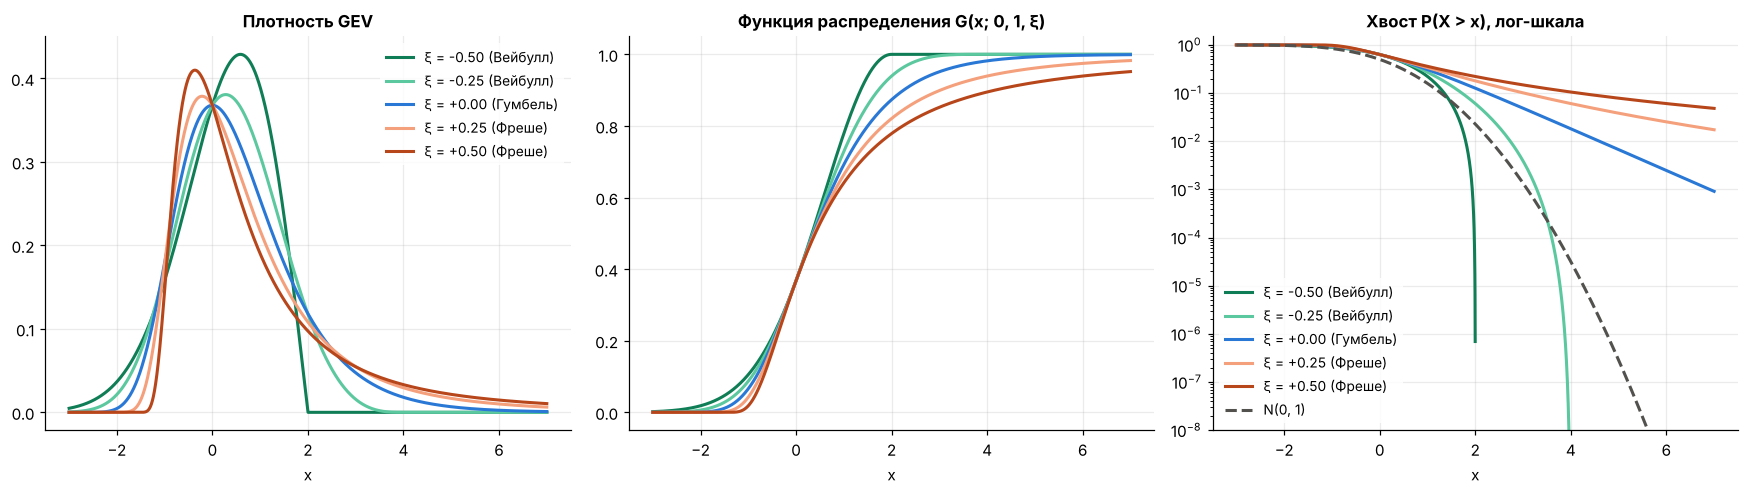

In [5]:
xis = [-0.5, -0.25, 0.0, 0.25, 0.5]
xi_colors = {-0.5: '#0f7d56', -0.25: '#5cc89f', 0.0: COLORS['gumbel'],
             0.25: '#f5a07c', 0.5: '#b8461b'}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
xs = np.linspace(-3, 7, 3000)
for xi in xis:
    d = stats.genextreme(c=-xi)
    label = f'ξ = {xi:+.2f}' + (' (Гумбель)' if xi == 0 else ' (Вейбулл)' if xi < 0 else ' (Фреше)')
    axes[0].plot(xs, d.pdf(xs), color=xi_colors[xi], label=label)
    axes[1].plot(xs, gev_cdf(xs, 0, 1, xi), color=xi_colors[xi], label=label)
    sf = d.sf(xs)
    axes[2].semilogy(xs, np.where(sf > 0, sf, np.nan), color=xi_colors[xi], label=label)
axes[2].semilogy(xs, stats.norm.sf(xs), color=COLORS['normal'], ls='--', label='N(0, 1)')

axes[0].set_title('Плотность GEV')
axes[1].set_title('Функция распределения G(x; 0, 1, ξ)')
axes[2].set_title('Хвост P(X > x), лог-шкала')
axes[2].set_ylim(1e-8, 1.5)
for ax in axes:
    ax.set_xlabel('x')
axes[0].legend()
axes[2].legend(loc='lower left')
fig.tight_layout()
plt.show()

Проверим численно предельный переход $\xi\to0$: максимальная разница между $G(x;0,1,\xi)$ и функцией Гумбеля убывает пропорционально $|\xi|$.

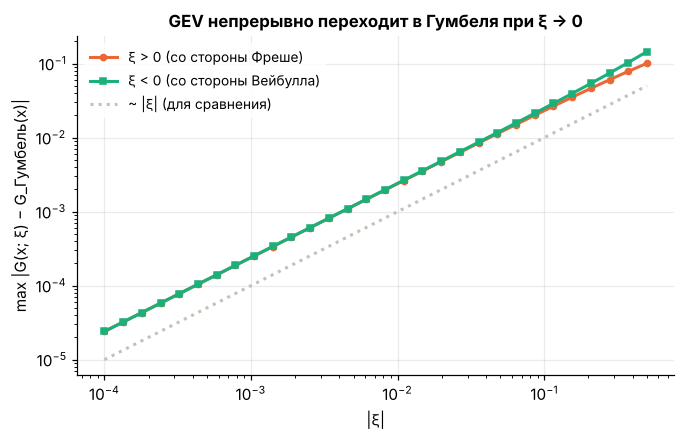

In [6]:
xs = np.linspace(-5, 15, 20001)
small_xis = np.logspace(-4, -0.3, 30)
gap_pos = [np.max(np.abs(gev_cdf(xs, 0, 1, xi) - gumbel_cdf(xs))) for xi in small_xis]
gap_neg = [np.max(np.abs(gev_cdf(xs, 0, 1, -xi) - gumbel_cdf(xs))) for xi in small_xis]

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(small_xis, gap_pos, 'o-', color=COLORS['frechet'], ms=4, label='ξ > 0 (со стороны Фреше)')
ax.loglog(small_xis, gap_neg, 's-', color=COLORS['weibull'], ms=4, label='ξ < 0 (со стороны Вейбулла)')
ax.loglog(small_xis, 0.1 * small_xis, color='#c3c2b7', ls=':', label='~ |ξ| (для сравнения)')
ax.set_xlabel('|ξ|')
ax.set_ylabel('max |G(x; ξ) − G_Гумбель(x)|')
ax.set_title('GEV непрерывно переходит в Гумбеля при ξ → 0')
ax.legend()
plt.show()

## 4. Временные ряды и годовые максимумы: теорема Фишера–Типпета в действии

Смоделируем 200 «лет» ежедневных наблюдений (по 365 значений в году) из трёх разных родительских распределений и возьмём **максимум за каждый год** (метод блочных максимумов, *block maxima*). Теория говорит, к какому типу должны сходиться максимумы, в зависимости только от **хвоста** родительского распределения:

| Сценарий | Родительское распределение | Хвост | Предел для максимумов | Теоретическое $\xi$ |
|---|---|---|---|---|
| Суточные осадки, мм | Gamma$(k=2,\ \theta=5)$ | экспоненциальный | Гумбель | $0$ |
| Суточные убытки портфеля | Стьюдент $t_{\nu=3}$ | степенной, $P(X>x)\sim x^{-3}$ | Фреше | $1/\nu = 1/3$ |
| Суточная нагрузка, доля от предела | Beta$(2, 3)$ | ограничен сверху единицей | Вейбулл | $-1/3$ |

(Для Beta$(a,b)$ вблизи правого конца $1-F(x)\sim c\,(1-x)^{b}$, поэтому $\xi=-1/b$.)

Для каждого сценария подгоним к 200 годовым максимумам:
- **GEV** методом максимального правдоподобия (`genextreme.fit`, с несколькими стартовыми точками — правдоподобие GEV бывает многоэкстремальным);
- **нормальный закон** с выборочными средним и стандартным отклонением — так поступил бы аналитик, «не знающий» теории экстремумов.

Поскольку модель данных известна, мы знаем и **истинное** распределение годового максимума: $P(M\le x)=F(x)^{365}$.

In [7]:
N_YEARS, BLOCK = 200, 365

scenarios = {
    'gumbel':  dict(title='Суточные осадки, Gamma(2, 5)',     unit='мм',
                    parent=stats.gamma(a=2, scale=5),      xi_theory=0.0,    attractor='Гумбель'),
    'frechet': dict(title='Суточные убытки, Student t(3)',    unit='усл. ед.',
                    parent=stats.t(df=3),                  xi_theory=1 / 3,  attractor='Фреше'),
    'weibull': dict(title='Суточная нагрузка, Beta(2, 3)',    unit='доля предела',
                    parent=stats.beta(2, 3),               xi_theory=-1 / 3, attractor='Вейбулл'),
}


def true_return_level(parent, T):
    """Истинный уровень, который годовой максимум превышает в среднем раз в T лет."""
    return parent.ppf((1 - 1 / np.asarray(T, float)) ** (1 / BLOCK))


def true_annual_max_pdf(parent, x):
    """Плотность годового максимума: d/dx F(x)^n = n F^(n-1) f."""
    return BLOCK * parent.cdf(x) ** (BLOCK - 1) * parent.pdf(x)


def fit_gev(data, starts=(-0.5, -0.2, 0.0, 0.2, 0.5, 1.0)):
    """ММП-оценка GEV с несколькими стартовыми точками.

    Правдоподобие GEV многоэкстремально: при ξ < 0 оптимизатор из старта по умолчанию
    легко застревает в плохом локальном максимуме. Берём лучший из нескольких запусков.
    Старт — либо число c0, либо готовая тройка (c0, loc0, scale0).
    Возвращает параметры в соглашении scipy: (c = -ξ, loc, scale)."""
    best_ll, best = -np.inf, None
    for start in starts:
        c0, loc0, scale0 = start if isinstance(start, tuple) else (start, np.mean(data), np.std(data))
        params = stats.genextreme.fit(data, c0, loc=loc0, scale=scale0)
        ll = stats.genextreme.logpdf(data, *params).sum()
        if np.isfinite(ll) and ll > best_ll:
            best_ll, best = ll, params
    return best


for key, sc in scenarios.items():
    sc['daily'] = sc['parent'].rvs(size=(N_YEARS, BLOCK), random_state=rng)
    sc['maxima'] = sc['daily'].max(axis=1)
    c, loc, scale = fit_gev(sc['maxima'])
    sc['gev_params'] = (c, loc, scale)
    sc['gev'] = stats.genextreme(c, loc, scale)
    sc['xi_hat'] = -c                      # переводим из соглашения scipy
    sc['norm'] = stats.norm(sc['maxima'].mean(), sc['maxima'].std(ddof=1))
    print(f'{sc["title"]:32s} ξ̂ = {sc["xi_hat"]:+.3f}   (теория: {sc["xi_theory"]:+.3f}, {sc["attractor"]})')

Суточные осадки, Gamma(2, 5)     ξ̂ = -0.020   (теория: +0.000, Гумбель)


Суточные убытки, Student t(3)    ξ̂ = +0.345   (теория: +0.333, Фреше)


Суточная нагрузка, Beta(2, 3)    ξ̂ = -0.361   (теория: -0.333, Вейбулл)


На рисунке для каждого сценария:

- **слева** — первые 8 лет исходного суточного ряда (серый), границы «лет» и годовые максимумы (красные точки);
- **в центре** — ряд годовых максимумов за все 200 лет и три оценки уровня «раз в 100 лет»: истинный, по GEV и по нормальной модели;
- **справа** — гистограмма годовых максимумов, подогнанные GEV и нормальный закон, истинная плотность максимума.

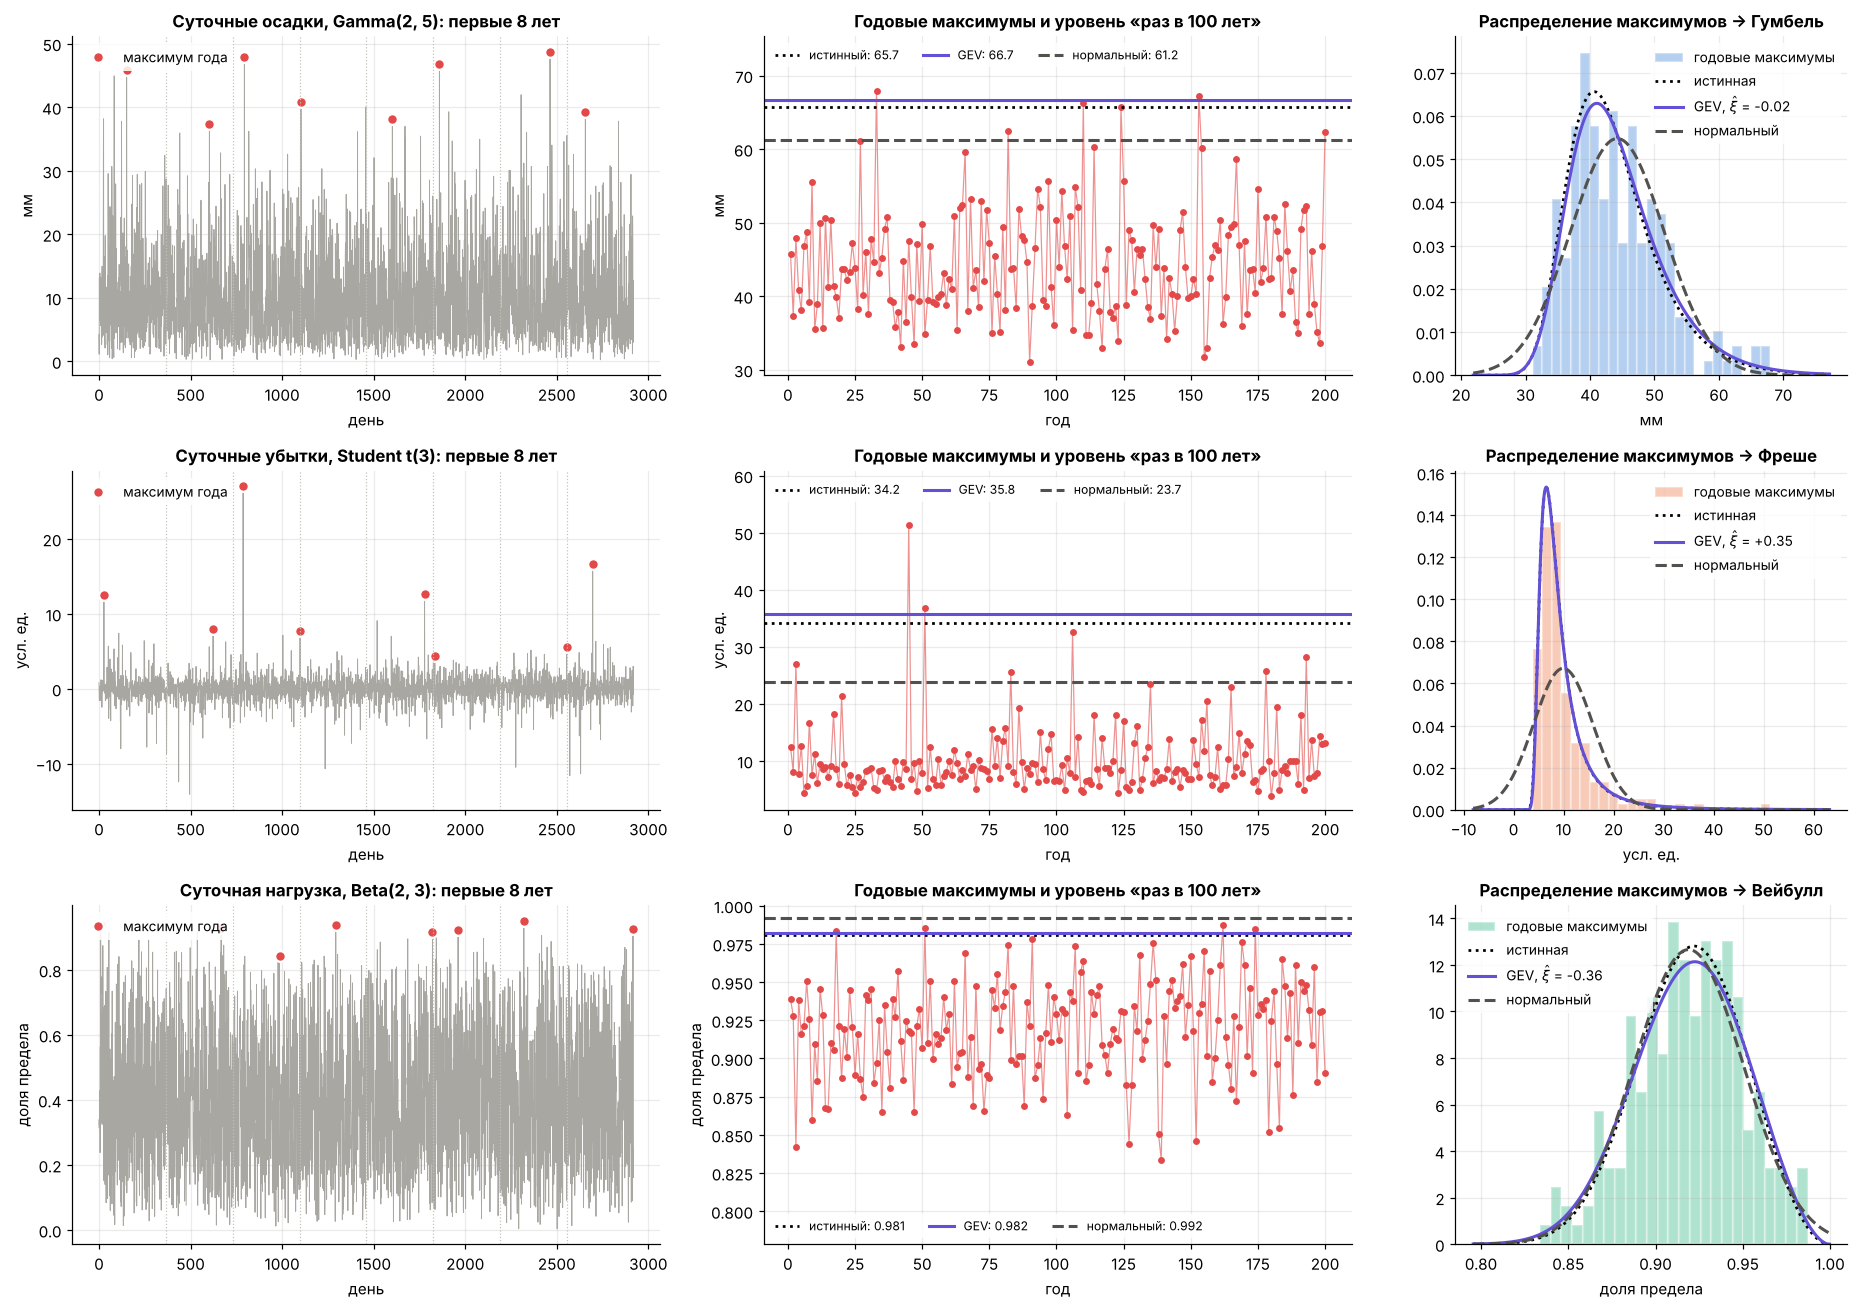

In [8]:
T_RETURN = 100
show_years = 8

fig, axes = plt.subplots(3, 3, figsize=(17, 12),
                         gridspec_kw={'width_ratios': [1.5, 1.5, 1]})
for i, (key, sc) in enumerate(scenarios.items()):
    daily, maxima = sc['daily'], sc['maxima']

    # (a) исходный временной ряд
    ax = axes[i, 0]
    series = daily[:show_years].ravel()
    days = np.arange(series.size)
    ax.plot(days, series, color=COLORS['data'], lw=0.6)
    argmax = daily[:show_years].argmax(axis=1) + np.arange(show_years) * BLOCK
    ax.plot(argmax, series[argmax], 'o', color=COLORS['max'], ms=7,
            markeredgecolor='white', markeredgewidth=1.5, label='максимум года')
    for y in range(1, show_years):
        ax.axvline(y * BLOCK, color='#c3c2b7', lw=0.8, ls=':')
    ax.set_title(f'{sc["title"]}: первые {show_years} лет')
    ax.set_xlabel('день')
    ax.set_ylabel(sc['unit'])
    ax.legend(loc='upper left')

    # (b) ряд годовых максимумов и уровень «раз в 100 лет»
    ax = axes[i, 1]
    years = np.arange(1, N_YEARS + 1)
    ax.plot(years, maxima, color=COLORS['max'], lw=0.8, alpha=0.6)
    ax.plot(years, maxima, 'o', color=COLORS['max'], ms=3.5)
    lvl_true = true_return_level(sc['parent'], T_RETURN)
    lvl_gev = sc['gev'].isf(1 / T_RETURN)
    lvl_norm = sc['norm'].isf(1 / T_RETURN)
    ax.axhline(lvl_true, color='black', ls=':', lw=1.8, label=f'истинный: {lvl_true:.3g}')
    ax.axhline(lvl_gev, color=COLORS['gev'], lw=2, label=f'GEV: {lvl_gev:.3g}')
    ax.axhline(lvl_norm, color=COLORS['normal'], ls='--', lw=2, label=f'нормальный: {lvl_norm:.3g}')
    ax.set_title(f'Годовые максимумы и уровень «раз в {T_RETURN} лет»')
    ax.set_xlabel('год')
    ax.set_ylabel(sc['unit'])
    top = max(maxima.max(), lvl_true, lvl_gev, lvl_norm)
    span = top - maxima.min()
    if key == 'weibull':
        # у Вейбулла всё прижато к верхней границе — легенду ставим вниз
        ax.set_ylim(maxima.min() - 0.35 * span, top + 0.05 * span)
        ax.legend(loc='lower left', ncol=3, fontsize=8)
    else:
        ax.set_ylim(top=top + 0.2 * span)
        ax.legend(loc='upper left', ncol=3, fontsize=8)

    # (c) гистограмма максимумов
    ax = axes[i, 2]
    ax.hist(maxima, bins=25, density=True, color=COLORS[key], alpha=0.35,
            edgecolor='white', linewidth=1.5, label='годовые максимумы')
    lo, hi = maxima.min(), maxima.max()
    pad = 0.25 * (hi - lo)
    xs = np.linspace(lo - pad, hi + pad, 600)
    if key == 'weibull':
        xs = xs[xs < 1]
    ax.plot(xs, true_annual_max_pdf(sc['parent'], xs), color='black', ls=':', lw=1.8, label='истинная')
    ax.plot(xs, sc['gev'].pdf(xs), color=COLORS['gev'], label=rf'GEV, $\hat\xi$ = {sc["xi_hat"]:+.2f}')
    ax.plot(xs, sc['norm'].pdf(xs), color=COLORS['normal'], ls='--', label='нормальный')
    ax.set_title(f'Распределение максимумов → {sc["attractor"]}')
    ax.set_xlabel(sc['unit'])
    ax.legend(loc='upper left' if key == 'weibull' else 'upper right')

fig.tight_layout()
plt.show()

**Что видно:**

- Исходные суточные ряды выглядят совершенно по-разному (асимметричные осадки, симметричные «пилообразные» убытки с редкими выбросами, ограниченная нагрузка), но **годовые максимумы во всех трёх случаях хорошо описываются одной и той же семьёй GEV** — меняется только знак $\xi$. Именно это и утверждает теорема Фишера–Типпета–Гнеденко.
- Оценки $\hat\xi$ близки к теоретическим: $\approx0$ для гамма-распределения, $>0$ для распределения Стьюдента, $<0$ для бета-распределения.
- Нормальная кривая симметрична и **не ловит асимметрию** максимумов: в сценарии Фреше она занижает уровень «раз в 100 лет» в разы, в сценарии Вейбулла — завышает (и может выйти за физический предел 1).

## 5. Уровни возврата: «паводок раз в $T$ лет»

Главный практический продукт теории экстремальных значений — **уровень возврата** $x_T$: значение, которое годовой максимум превышает в среднем один раз за $T$ лет, т.е. $P(M > x_T) = 1/T$. Для GEV

$$x_T = \mu - \frac{\sigma}{\xi}\Bigl[1-\bigl(-\ln(1-1/T)\bigr)^{-\xi}\Bigr],\qquad \xi\ne0.$$

На графике уровней возврата (ось $T$ — логарифмическая):
- у Гумбеля зависимость линейна по $\ln T$,
- у Фреше — выпукла (рост без предела, всё быстрее),
- у Вейбулла — вогнута и упирается в верхнюю границу.

Точки — эмпирические уровни (позиции построения $p_i = i/(n+1)$). Затенённая полоса — 95% бутстреп-интервал для уровня по GEV: он показывает, насколько неопределённа экстраполяция за пределы наблюдённых 200 лет.

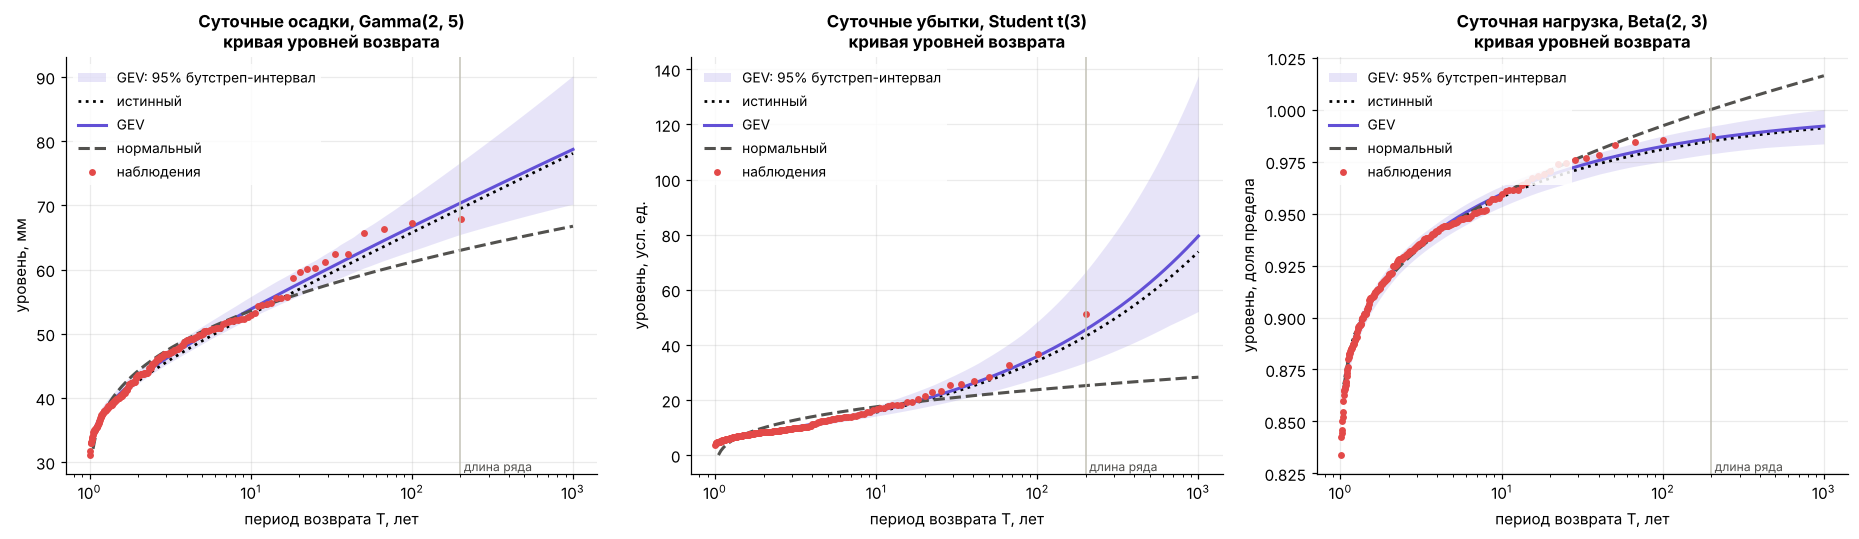

In [9]:
T_grid = np.logspace(np.log10(1.05), 3, 200)   # от ~1 года до 1000 лет
N_BOOT = 150

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (key, sc) in zip(axes, scenarios.items()):
    maxima = np.sort(sc['maxima'])
    p_emp = np.arange(1, N_YEARS + 1) / (N_YEARS + 1)
    T_emp = 1 / (1 - p_emp)

    # бутстреп по годам
    boot = np.empty((N_BOOT, T_grid.size))
    for b in range(N_BOOT):
        sample = rng.choice(maxima, size=N_YEARS, replace=True)
        cb, lb, sb = fit_gev(sample, starts=[sc['gev_params']])   # старт из оценки по всем данным
        boot[b] = stats.genextreme(cb, lb, sb).isf(1 / T_grid)
    lo_band, hi_band = np.percentile(boot, [2.5, 97.5], axis=0)

    ax.fill_between(T_grid, lo_band, hi_band, color=COLORS['gev'], alpha=0.15, lw=0,
                    label='GEV: 95% бутстреп-интервал')
    ax.semilogx(T_grid, true_return_level(sc['parent'], T_grid), color='black', ls=':', lw=1.8,
                label='истинный')
    ax.semilogx(T_grid, sc['gev'].isf(1 / T_grid), color=COLORS['gev'], label='GEV')
    ax.semilogx(T_grid, sc['norm'].isf(1 / T_grid), color=COLORS['normal'], ls='--', label='нормальный')
    ax.semilogx(T_emp, maxima, 'o', color=COLORS['max'], ms=3.5, label='наблюдения')
    ax.axvline(N_YEARS, color='#c3c2b7', lw=1)
    ax.text(N_YEARS, ax.get_ylim()[0], ' длина ряда', fontsize=8, color='#52514e', va='bottom')
    ax.set_title(f'{sc["title"]}\nкривая уровней возврата')
    ax.set_xlabel('период возврата T, лет')
    ax.set_ylabel(f'уровень, {sc["unit"]}')
    ax.legend(loc='upper left')
fig.tight_layout()
plt.show()

Переведём ошибку в понятные термины. Нормальная модель называет некоторый уровень «событием раз в 100 (1000) лет». Как часто такой уровень превышается **на самом деле**? Истинный период возврата для уровня $x$ равен $1/\bigl(1-F(x)^{365}\bigr)$.

In [10]:
def true_return_period(parent, level):
    p_exceed = 1 - parent.cdf(level) ** BLOCK
    return np.inf if p_exceed <= 0 else 1 / p_exceed


print(f'{"сценарий":32s}{"T":>6s}{"истинный":>11s}{"GEV":>9s}{"норм.":>9s}'
      f'{"реальный период для норм. уровня, лет":>40s}')
for key, sc in scenarios.items():
    for T in (100, 1000):
        lvl_true = true_return_level(sc['parent'], T)
        lvl_gev = sc['gev'].isf(1 / T)
        lvl_norm = sc['norm'].isf(1 / T)
        T_real = true_return_period(sc['parent'], lvl_norm)
        T_real_str = '∞ (уровень выше предела)' if not np.isfinite(T_real) else f'{T_real:,.0f}'
        print(f'{sc["title"]:32s}{T:6d}{lvl_true:11.3f}{lvl_gev:9.3f}{lvl_norm:9.3f}{T_real_str:>40s}')

сценарий                             T   истинный      GEV    норм.   реальный период для норм. уровня, лет
Суточные осадки, Gamma(2, 5)       100     65.749   66.665   61.177                                      43
Суточные осадки, Gamma(2, 5)      1000     78.088   78.715   66.743                                     120
Суточные убытки, Student t(3)      100     34.178   35.802   23.748                                      34
Суточные убытки, Student t(3)     1000     73.803   79.492   28.285                                      57
Суточная нагрузка, Beta(2, 3)      100      0.981    0.982    0.992                                   1,484
Суточная нагрузка, Beta(2, 3)     1000      0.991    0.992    1.016                ∞ (уровень выше предела)


**Вывод:**

- **Тяжёлый хвост (Фреше).** Уровень, который нормальная модель считает событием «раз в 1000 лет», на деле превышается в разы чаще — порядка раза в несколько десятков лет. Именно так недооцениваются финансовые кризисы и катастрофические убытки.
- **Экспоненциальный хвост (Гумбель).** Нормальная модель тоже занижает редкие уровни, хотя и не так драматично; ошибка растёт с $T$.
- **Ограниченный хвост (Вейбулл).** Нормальная модель переоценивает экстремумы и может назначить «уровень раз в 1000 лет» выше физического предела — конструкцию будут проектировать с избыточным запасом, а вероятность отказа оценят неверно.
- GEV-оценки близки к истинным внутри наблюдённого диапазона, но бутстреп-интервал быстро расширяется при $T \gg 200$ лет: **экстраполяция в хвост всегда неопределённа**, и это надо честно показывать.

## 6. ЦПТ против теории экстремальных значений на одних и тех же данных

Возьмём тот же ряд суточных убытков $t_3$. Распределение Стьюдента с $\nu=3$ имеет конечную дисперсию, поэтому:

- **годовая сумма** убытков по ЦПТ близка к нормальной;
- **годовой максимум** сходится к Фреше — и нормальным не становится никогда, сколько бы дней ни было в году.

Q–Q график против нормального закона делает разницу наглядной: точки сумм ложатся на прямую, точки максимумов — загибаются вверх в правом хвосте.

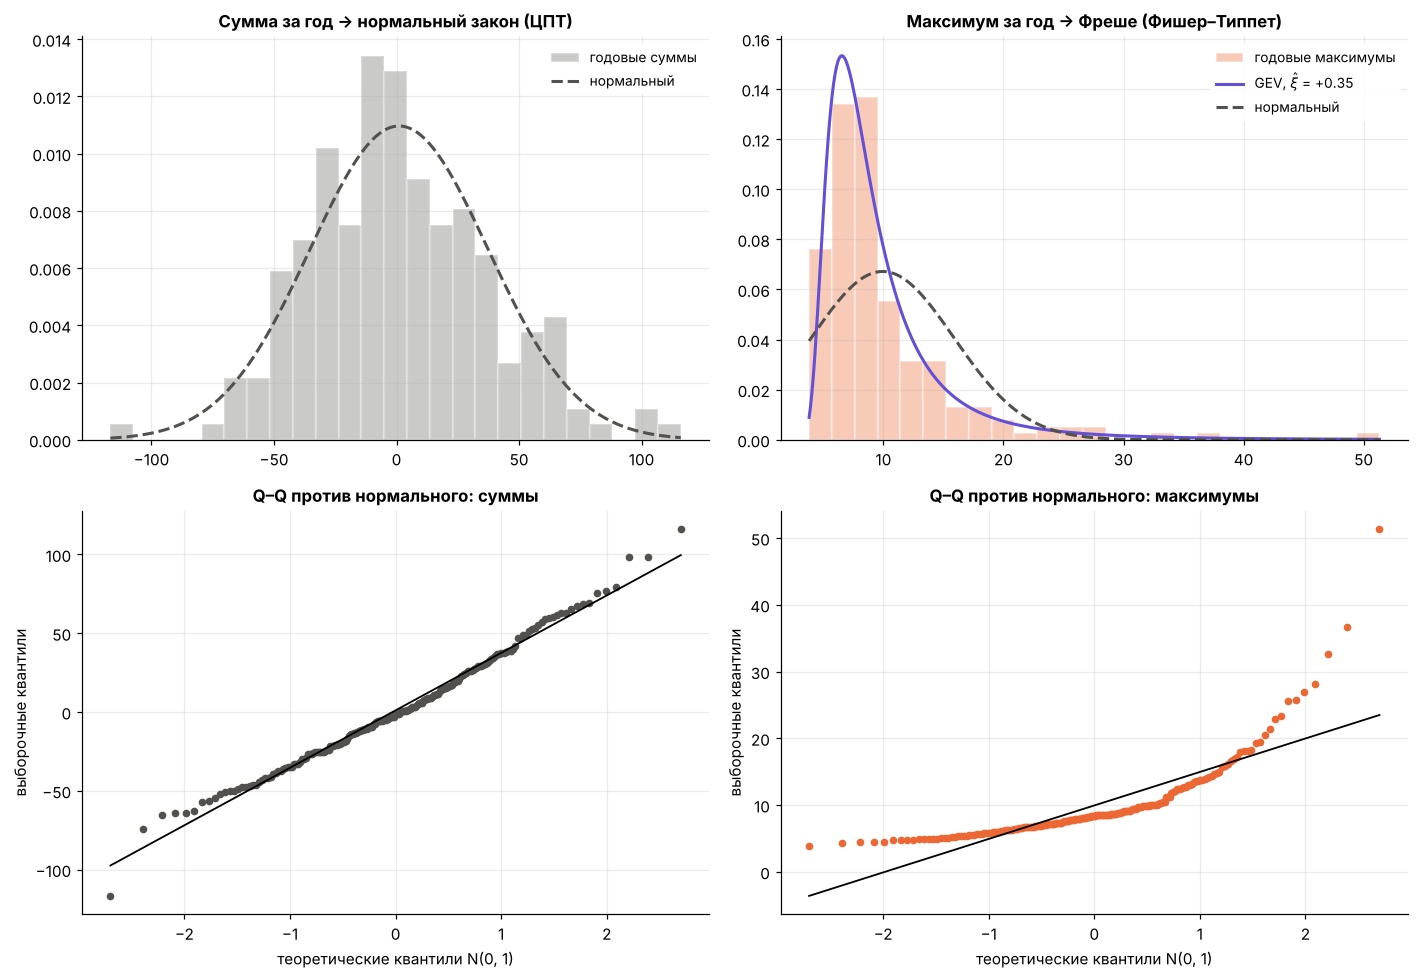

Тест Шапиро–Уилка на нормальность: суммы p = 0.189, максимумы p = 2.1e-18


In [11]:
sc = scenarios['frechet']
sums = sc['daily'].sum(axis=1)
maxima = sc['maxima']

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

ax = axes[0, 0]
ax.hist(sums, bins=25, density=True, color=COLORS['normal'], alpha=0.3, edgecolor='white', linewidth=1.5,
        label='годовые суммы')
xs = np.linspace(sums.min(), sums.max(), 400)
ax.plot(xs, stats.norm(sums.mean(), sums.std(ddof=1)).pdf(xs), color=COLORS['normal'], ls='--',
        label='нормальный')
ax.set_title('Сумма за год → нормальный закон (ЦПТ)')
ax.legend()

ax = axes[0, 1]
ax.hist(maxima, bins=25, density=True, color=COLORS['frechet'], alpha=0.35, edgecolor='white', linewidth=1.5,
        label='годовые максимумы')
xs = np.linspace(maxima.min(), maxima.max(), 400)
ax.plot(xs, sc['gev'].pdf(xs), color=COLORS['gev'], label=rf'GEV, $\hat\xi$ = {sc["xi_hat"]:+.2f}')
ax.plot(xs, sc['norm'].pdf(xs), color=COLORS['normal'], ls='--', label='нормальный')
ax.set_title('Максимум за год → Фреше (Фишер–Типпет)')
ax.legend()

for ax, data, color, name in [(axes[1, 0], sums, COLORS['normal'], 'суммы'),
                              (axes[1, 1], maxima, COLORS['frechet'], 'максимумы')]:
    (osm, osr), (slope, intercept, r) = stats.probplot(data, dist='norm')
    ax.plot(osm, osr, 'o', color=color, ms=4)
    ax.plot(osm, slope * osm + intercept, color='black', lw=1.2)
    ax.set_title(f'Q–Q против нормального: {name}')
    ax.set_xlabel('теоретические квантили N(0, 1)')
    ax.set_ylabel('выборочные квантили')

fig.tight_layout()
plt.show()

print(f'Тест Шапиро–Уилка на нормальность: суммы p = {stats.shapiro(sums).pvalue:.3f}, '
      f'максимумы p = {stats.shapiro(maxima).pvalue:.1e}')

## Итоги

| | Гумбель (тип I) | Фреше (тип II) | Вейбулл (тип III) | Нормальный закон |
|---|---|---|---|---|
| Форма GEV | $\xi = 0$ | $\xi > 0$ | $\xi < 0$ | — (не предел для максимумов) |
| Хвост | экспоненциальный | степенной $x^{-1/\xi}$ | ограничен сверху | гауссов, $e^{-x^2/2}$ |
| Чьи максимумы сходятся сюда | нормальное, экспоненциальное, гамма, логнормальное | Парето, Стьюдент, Коши, логгамма | равномерное, бета, любое ограниченное сверху | — |
| Типичные экстремумы | паводки, температуры, осадки | финансовые потери, катастрофы, доходы | прочность, ресурс, ограниченные нагрузки | описывает суммы и средние (ЦПТ) |
| Ошибка нормальной модели | занижает редкие уровни | сильно занижает (в разы и порядки) | завышает, игнорирует предел | — |

Главное:

1. **Суммы → нормальный закон (ЦПТ); максимумы → GEV (Фишер–Типпет–Гнеденко).** Это две разные предельные теоремы; применять первую к задачам второй — методическая ошибка.
2. Тип предельного распределения определяется только **хвостом** исходных данных, и все три типа охватываются одним параметром формы $\xi$.
3. Самое ценное, что даёт теория, — обоснованная **экстраполяция в хвост**: уровни возврата для событий, которые ещё ни разу не наблюдались. Нормальная модель здесь систематически ошибается, причём тем сильнее, чем реже событие.
4. Оценка $\xi$ и уровней возврата неопределённа — всегда сопровождайте её доверительным интервалом (бутстреп, профильное правдоподобие).